# Multi-label ResNet1D for MI Anatomical Localization

In [1]:
from __future__ import annotations

import json
import logging
import random
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import wfdb

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    multilabel_confusion_matrix,
)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 6
NUM_WORKERS = 0
EXPECTED_SAMPLES = 5000
EXPECTED_LEADS = 12
SAMPLING_RATE = 500

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("mi_localization_resnet")

print("Device:", DEVICE)


Device: cuda


## Step 1: Resolve project paths and load the Notebook 09 manifest

In [2]:
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (p / "data" / "raw" / "ptb-xl").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find project root containing data/raw/ptb-xl.")

DATASET_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"
MANIFEST_PATH = (
    PROJECT_ROOT / "data" / "processed" / "localization"
    / "localization_dataset_manifest.csv"
)
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {MANIFEST_PATH}. Run Notebook 09 successfully first."
    )

OUTPUT_DIR = PROJECT_ROOT / "results" / "localization_resnet1d"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(MANIFEST_PATH)
TARGET_COLUMNS = [
    "loc_inferior",
    "loc_anterior",
    "loc_anteroseptal",
    "loc_anterolateral",
    "loc_lateral",
    "loc_posterior",
    "loc_inferoposterior",
]
required = {"ecg_id", "patient_id", "dataset_split", "filename_hr", *TARGET_COLUMNS}
missing = required.difference(manifest.columns)
if missing:
    raise ValueError(f"Manifest missing columns: {sorted(missing)}")

manifest["dataset_split"] = manifest["dataset_split"].astype(str).str.lower().str.strip()
manifest["dataset_split"] = manifest["dataset_split"].replace({"val": "validation"})
for col in TARGET_COLUMNS:
    manifest[col] = pd.to_numeric(manifest[col], errors="raise").astype(np.float32)

print("Project root:", PROJECT_ROOT)
print("Manifest rows:", len(manifest))
display(manifest.head())


Project root: c:\Users\sintu\Desktop\Myocardial Infarction
Manifest rows: 4953


,ecg_id,patient_id,dataset_split,filename_hr,loc_inferior,loc_anterior,loc_anteroseptal,loc_anterolateral,loc_lateral,loc_posterior,loc_inferoposterior
0,8,11275.0,validation,records500/00000/00008_hr,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,39,13619.0,validation,records500/00000/00039_hr,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,63,15265.0,test,records500/00000/00063_hr,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,77,8555.0,train,records500/00000/00077_hr,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,103,13722.0,train,records500/00000/00103_hr,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 2: Split and patient-leakage validation

In [3]:
train_df = manifest.loc[manifest.dataset_split == "train"].copy()
val_df = manifest.loc[manifest.dataset_split == "validation"].copy()
test_df = manifest.loc[manifest.dataset_split == "test"].copy()

for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    if frame.empty:
        raise ValueError(f"{name} split is empty.")

patient_sets = {
    name: set(frame.patient_id.dropna().unique())
    for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]
}
if patient_sets["train"] & patient_sets["validation"]:
    raise ValueError("Patient leakage between train and validation.")
if patient_sets["train"] & patient_sets["test"]:
    raise ValueError("Patient leakage between train and test.")
if patient_sets["validation"] & patient_sets["test"]:
    raise ValueError("Patient leakage between validation and test.")

print("Patient-level separation check passed.")
print("Record counts:", {"train": len(train_df), "validation": len(val_df), "test": len(test_df)})
display(pd.DataFrame({
    "train_positive": train_df[TARGET_COLUMNS].sum(),
    "validation_positive": val_df[TARGET_COLUMNS].sum(),
    "test_positive": test_df[TARGET_COLUMNS].sum(),
}))


Patient-level separation check passed.
Record counts: {'train': 3969, 'validation': 484, 'test': 500}


,train_positive,validation_positive,test_positive
loc_inferior,2529.0,313.0,315.0
loc_anterior,271.0,28.0,31.0
loc_anteroseptal,1773.0,228.0,225.0
loc_anterolateral,231.0,29.0,27.0
loc_lateral,417.0,51.0,53.0
loc_posterior,76.0,11.0,10.0
loc_inferoposterior,0.0,0.0,0.0


## Step 3: Dataset and ECG loading

In [4]:
def load_ecg(relative_path: str) -> np.ndarray:
    """Load a 500 Hz, 12-lead PTB-XL record and return normalized (12, 5000)."""
    record_path = DATASET_DIR / str(relative_path)
    if record_path.suffix:
        record_path = record_path.with_suffix("")
    header_path = record_path.with_suffix(".hea")
    if not header_path.is_file():
        raise FileNotFoundError(f"WFDB header not found: {header_path}")

    signal, fields = wfdb.rdsamp(str(record_path))
    signal = np.asarray(signal, dtype=np.float32)
    if signal.shape != (EXPECTED_SAMPLES, EXPECTED_LEADS):
        raise ValueError(
            f"Unexpected signal shape {signal.shape} for {relative_path}; "
            f"expected {(EXPECTED_SAMPLES, EXPECTED_LEADS)}."
        )
    if int(fields.get("fs", -1)) != SAMPLING_RATE:
        raise ValueError(f"Expected 500 Hz, got {fields.get('fs')} Hz for {relative_path}.")

    signal = signal.T
    mean = signal.mean(axis=1, keepdims=True)
    std = np.maximum(signal.std(axis=1, keepdims=True), 1e-6)
    signal = (signal - mean) / std
    if not np.isfinite(signal).all():
        raise ValueError(f"Non-finite signal values in {relative_path}.")
    return signal.astype(np.float32)


class PTBXLLocalizationDataset(Dataset):
    """Lazy-loading ECG dataset for multi-label territory classification."""

    def __init__(self, frame: pd.DataFrame) -> None:
        self.frame = frame.reset_index(drop=True).copy()

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        row = self.frame.iloc[index]
        x = torch.from_numpy(load_ecg(row["filename_hr"]))
        y = torch.tensor(row[TARGET_COLUMNS].to_numpy(dtype=np.float32))
        return x, y


train_loader = DataLoader(
    PTBXLLocalizationDataset(train_df), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    PTBXLLocalizationDataset(val_df), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    PTBXLLocalizationDataset(test_df), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
)

xb, yb = next(iter(train_loader))
print("ECG batch:", tuple(xb.shape))
print("Target batch:", tuple(yb.shape))
assert xb.shape[1:] == (EXPECTED_LEADS, EXPECTED_SAMPLES)
assert yb.shape[1] == len(TARGET_COLUMNS)


ECG batch: (32, 12, 5000)
Target batch: (32, 7)


## Step 4: Define the ResNet1D architecture

In [5]:
class ResidualBlock1D(nn.Module):
    """Two-layer 1D residual block with an optional projection shortcut."""

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1) -> None:
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels, out_channels, kernel_size=7,
            stride=stride, padding=3, bias=False,
        )
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(
            out_channels, out_channels, kernel_size=5,
            stride=1, padding=2, bias=False,
        )
        self.bn2 = nn.BatchNorm1d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class MIResNet1D(nn.Module):
    """Compact ResNet1D returning one logit per MI territory."""

    def __init__(self, num_classes: int = 7) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )
        self.layer1 = nn.Sequential(
            ResidualBlock1D(32, 32),
            ResidualBlock1D(32, 32),
        )
        self.layer2 = nn.Sequential(
            ResidualBlock1D(32, 64, stride=2),
            ResidualBlock1D(64, 64),
        )
        self.layer3 = nn.Sequential(
            ResidualBlock1D(64, 128, stride=2),
            ResidualBlock1D(128, 128),
        )
        self.layer4 = nn.Sequential(
            ResidualBlock1D(128, 192, stride=2),
            ResidualBlock1D(192, 192),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.35)
        self.classifier = nn.Linear(192, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x).squeeze(-1)
        return self.classifier(self.dropout(x))


model = MIResNet1D(num_classes=len(TARGET_COLUMNS)).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


MIResNet1D(
  (stem): Sequential(
    (0): Conv1d(12, 32, kernel_size=(15,), stride=(2,), padding=(7,), bias=False)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool1d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): ResidualBlock1D(
      (conv1): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): ResidualBlock1D(
      (conv1): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, a

## Step 5: Loss, optimizer, and class-imbalance handling

In [ ]:
positive = train_df[TARGET_COLUMNS].sum(axis=0).to_numpy(dtype=np.float32)
negative = len(train_df) - positive

pos_weight_values = np.divide(
    negative,
    np.maximum(positive, 1.0),
)
pos_weight_values = np.clip(pos_weight_values, 1.0, 10.0)

pos_weight = torch.tensor(pos_weight_values, dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

print("Positive weights by class:")
display(pd.DataFrame({"territory": TARGET_COLUMNS, "pos_weight": pos_weight_values}))


Positive weights by class:


,territory,pos_weight
0,loc_inferior,1.000000
1,loc_anterior,10.000000
2,loc_anteroseptal,1.238579
3,loc_anterolateral,10.000000
4,loc_lateral,8.517985
5,loc_posterior,10.000000
6,loc_inferoposterior,10.000000


## Step 6: Training and validation functions

In [7]:
def run_epoch(
    loader: DataLoader,
    training: bool,
) -> tuple[float, np.ndarray, np.ndarray]:
    """Run one training or validation epoch and return loss, labels, probabilities."""
    model.train(training)
    total_loss = 0.0
    all_targets: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for signals, targets in loader:
        signals = signals.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(signals)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_loss += loss.item() * signals.size(0)
        probabilities = torch.sigmoid(logits).detach().cpu().numpy()
        all_probabilities.append(probabilities)
        all_targets.append(targets.detach().cpu().numpy())

    mean_loss = total_loss / len(loader.dataset)
    return (
        mean_loss,
        np.concatenate(all_targets, axis=0),
        np.concatenate(all_probabilities, axis=0),
    )


def safe_macro_auc(y_true: np.ndarray, y_prob: np.ndarray) -> float:
    """Calculate macro ROC-AUC over classes containing both target values."""
    scores = []
    for class_index in range(y_true.shape[1]):
        if np.unique(y_true[:, class_index]).size == 2:
            scores.append(roc_auc_score(y_true[:, class_index], y_prob[:, class_index]))
    return float(np.mean(scores)) if scores else float("nan")


## Step 7: Train with early stopping

In [8]:
history: list[dict[str, float]] = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_checkpoint_path = CHECKPOINT_DIR / "mi_localization_resnet1d_best.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss, _, _ = run_epoch(train_loader, training=True)
    val_loss, val_true, val_prob = run_epoch(val_loader, training=False)
    val_macro_auc = safe_macro_auc(val_true, val_prob)
    scheduler.step(val_loss)

    row = {
        "epoch": float(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_macro_roc_auc": float(val_macro_auc),
        "learning_rate": float(optimizer.param_groups[0]["lr"]),
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"val_macro_roc_auc={val_macro_auc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "target_columns": TARGET_COLUMNS,
                "best_val_loss": best_val_loss,
                "seed": SEED,
            },
            best_checkpoint_path,
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Checkpoint:", best_checkpoint_path)


Epoch 01/25 | train_loss=0.6161 | val_loss=0.5420 | val_macro_roc_auc=0.8549
Epoch 02/25 | train_loss=0.5274 | val_loss=0.5628 | val_macro_roc_auc=0.8478
Epoch 03/25 | train_loss=0.4766 | val_loss=0.5199 | val_macro_roc_auc=0.9004
Epoch 04/25 | train_loss=0.4527 | val_loss=0.6471 | val_macro_roc_auc=0.8981
Epoch 05/25 | train_loss=0.4310 | val_loss=0.4269 | val_macro_roc_auc=0.9092
Epoch 06/25 | train_loss=0.4085 | val_loss=0.9751 | val_macro_roc_auc=0.8645
Epoch 07/25 | train_loss=0.3937 | val_loss=0.5272 | val_macro_roc_auc=0.9080
Epoch 08/25 | train_loss=0.3833 | val_loss=0.4704 | val_macro_roc_auc=0.9079
Epoch 09/25 | train_loss=0.3348 | val_loss=0.4275 | val_macro_roc_auc=0.9239
Epoch 10/25 | train_loss=0.3370 | val_loss=0.4152 | val_macro_roc_auc=0.9205
Epoch 11/25 | train_loss=0.3226 | val_loss=0.4454 | val_macro_roc_auc=0.9186
Epoch 12/25 | train_loss=0.3193 | val_loss=0.4687 | val_macro_roc_auc=0.9092
Epoch 13/25 | train_loss=0.3073 | val_loss=0.4747 | val_macro_roc_auc=0.9198

## Step 8: Plot training curves

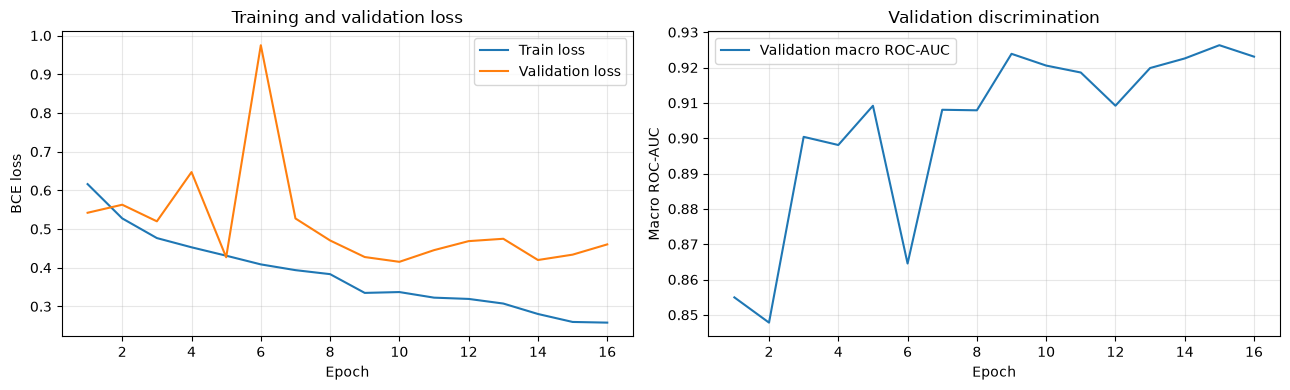

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[0].set_title("Training and validation loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_roc_auc"],
    label="Validation macro ROC-AUC",
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro ROC-AUC")
axes[1].set_title("Validation discrimination")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 9: Select per-class thresholds using validation data only

In [10]:
checkpoint = torch.load(best_checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])

val_loss, y_val, p_val = run_epoch(val_loader, training=False)

def choose_f1_thresholds(
    y_true: np.ndarray,
    y_prob: np.ndarray,
) -> np.ndarray:
    """Choose an F1-maximizing threshold independently for each class on validation data."""
    thresholds = np.full(y_true.shape[1], 0.5, dtype=np.float32)
    candidates = np.linspace(0.10, 0.90, 17)

    for class_index in range(y_true.shape[1]):
        if y_true[:, class_index].sum() == 0:
            continue
        best_score = -1.0
        best_threshold = 0.5
        for threshold in candidates:
            prediction = (y_prob[:, class_index] >= threshold).astype(int)
            score = f1_score(
                y_true[:, class_index],
                prediction,
                zero_division=0,
            )
            if score > best_score:
                best_score = score
                best_threshold = float(threshold)
        thresholds[class_index] = best_threshold

    return thresholds

thresholds = choose_f1_thresholds(y_val, p_val)
threshold_table = pd.DataFrame({
    "territory": TARGET_COLUMNS,
    "validation_selected_threshold": thresholds,
})
display(threshold_table)
threshold_table.to_csv(OUTPUT_DIR / "validation_thresholds.csv", index=False)


,territory,validation_selected_threshold
0,loc_inferior,0.45
1,loc_anterior,0.60
2,loc_anteroseptal,0.35
3,loc_anterolateral,0.60
4,loc_lateral,0.75
5,loc_posterior,0.90
6,loc_inferoposterior,0.50


## Step 10: Final held-out test evaluation

In [11]:
test_loss, y_test, p_test = run_epoch(test_loader, training=False)
y_pred = (p_test >= thresholds.reshape(1, -1)).astype(int)

per_class_rows = []
for index, territory in enumerate(TARGET_COLUMNS):
    y_true_class = y_test[:, index]
    y_pred_class = y_pred[:, index]
    y_prob_class = p_test[:, index]

    if np.unique(y_true_class).size == 2:
        class_auc = roc_auc_score(y_true_class, y_prob_class)
        class_ap = average_precision_score(y_true_class, y_prob_class)
    else:
        class_auc = float("nan")
        class_ap = float("nan")

    per_class_rows.append({
        "territory": territory,
        "threshold": float(thresholds[index]),
        "precision": precision_score(y_true_class, y_pred_class, zero_division=0),
        "sensitivity_recall": recall_score(y_true_class, y_pred_class, zero_division=0),
        "specificity": (
            (np.sum((y_true_class == 0) & (y_pred_class == 0)) /
             max(np.sum(y_true_class == 0), 1))
        ),
        "f1": f1_score(y_true_class, y_pred_class, zero_division=0),
        "roc_auc": class_auc,
        "pr_auc_average_precision": class_ap,
        "support_positive": int(y_true_class.sum()),
    })

per_class_metrics = pd.DataFrame(per_class_rows)
display(per_class_metrics)

aggregate_metrics = {
    "test_loss": float(test_loss),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
    "micro_f1": float(f1_score(y_test, y_pred, average="micro", zero_division=0)),
    "macro_precision": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_sensitivity": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_roc_auc": safe_macro_auc(y_test, p_test),
    "macro_pr_auc": float(np.nanmean(per_class_metrics["pr_auc_average_precision"])),
    "exact_match_accuracy": float(accuracy_score(y_test, y_pred)),
    "hamming_accuracy": float(1.0 - np.mean(y_test != y_pred)),
}
print(json.dumps(aggregate_metrics, indent=2))

per_class_metrics.to_csv(OUTPUT_DIR / "per_class_test_metrics.csv", index=False)
(OUTPUT_DIR / "aggregate_test_metrics.json").write_text(
    json.dumps(aggregate_metrics, indent=2), encoding="utf-8"
)


,territory,threshold,precision,sensitivity_recall,specificity,f1,roc_auc,pr_auc_average_precision,support_positive
0,loc_inferior,0.45,0.856734,0.949206,0.729730,0.900602,0.943921,0.966579,315
1,loc_anterior,0.60,0.403226,0.806452,0.921109,0.537634,0.920971,0.540994,31
2,loc_anteroseptal,0.35,0.849421,0.977778,0.858182,0.909091,0.964477,0.945318,225
3,loc_anterolateral,0.60,0.533333,0.592593,0.970402,0.561404,0.934774,0.683526,27
4,loc_lateral,0.75,0.450704,0.603774,0.912752,0.516129,0.867038,0.613248,53
5,loc_posterior,0.90,0.500000,0.100000,0.997959,0.166667,0.855306,0.342093,10
6,loc_inferoposterior,0.50,0.000000,0.000000,1.000000,0.000000,NaN,NaN,0


{
  "test_loss": 0.4357010943889618,
  "macro_f1": 0.5130752764326106,
  "micro_f1": 0.8270571827057183,
  "macro_precision": 0.5133453912733156,
  "macro_sensitivity": 0.5756859881979437,
  "macro_roc_auc": 0.9144145580522188,
  "macro_pr_auc": 0.6819595220183688,
  "exact_match_accuracy": 0.622,
  "hamming_accuracy": 0.9291428571428572
}


341

## Step 11: Confusion matrices and prediction outputs

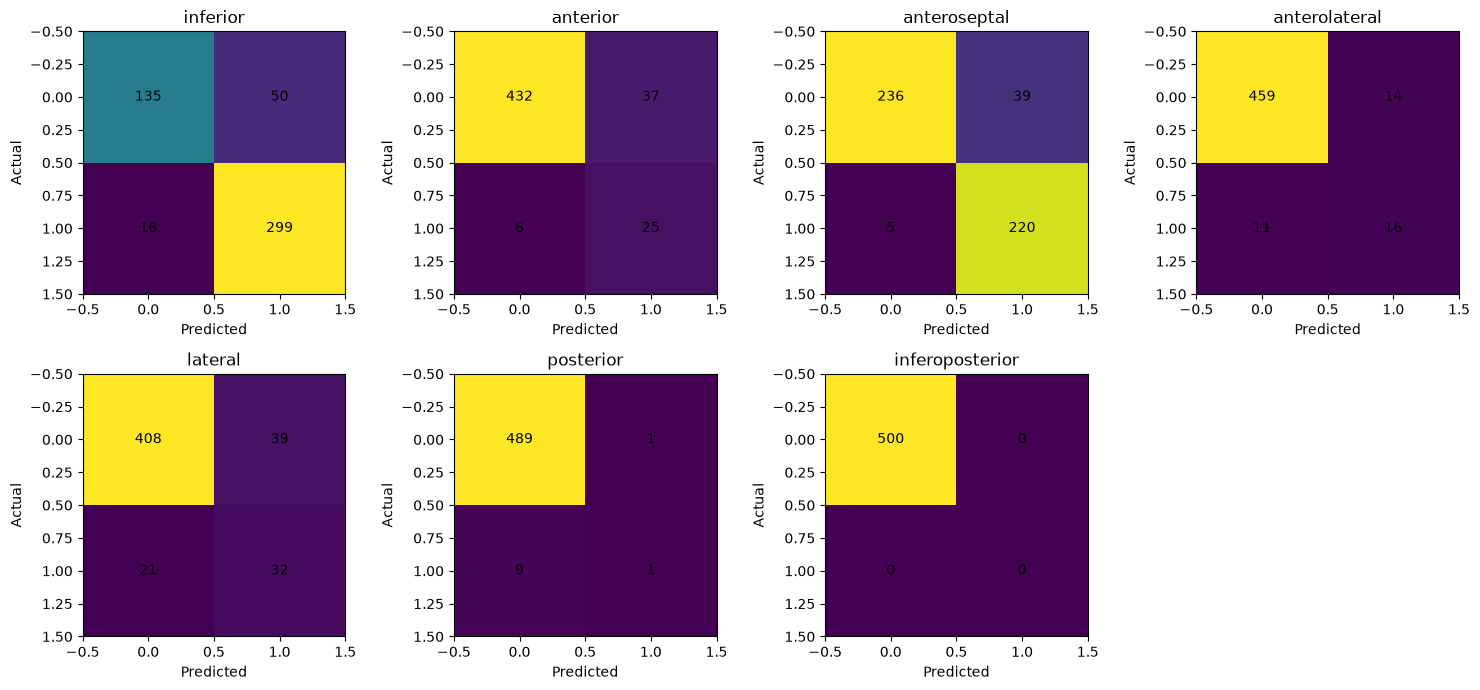

Saved test predictions to: c:\Users\sintu\Desktop\Myocardial Infarction\results\localization_resnet1d\test_predictions.csv


In [12]:
cms = multilabel_confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for index, ax in enumerate(axes.flat):
    if index >= len(TARGET_COLUMNS):
        ax.axis("off")
        continue
    cm = cms[index]
    ax.imshow(cm)
    ax.set_title(TARGET_COLUMNS[index].replace("loc_", ""))
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

prediction_frame = pd.DataFrame(p_test, columns=[f"prob_{c}" for c in TARGET_COLUMNS])
for index, col in enumerate(TARGET_COLUMNS):
    prediction_frame[f"pred_{col}"] = y_pred[:, index]
prediction_frame.insert(0, "ecg_id", test_df["ecg_id"].to_numpy())
prediction_frame.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

print("Saved test predictions to:", OUTPUT_DIR / "test_predictions.csv")


## Step 12: Save reproducibility metadata and final status

In [13]:
run_metadata = {
    "architecture": "compact_resnet1d",
    "seed": SEED,
    "sampling_rate_hz": SAMPLING_RATE,
    "input_shape_per_record": [EXPECTED_LEADS, EXPECTED_SAMPLES],
    "target_columns": TARGET_COLUMNS,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val_loss),
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "train_records": int(len(train_df)),
    "validation_records": int(len(val_df)),
    "test_records": int(len(test_df)),
    "test_metrics": aggregate_metrics,
}
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(run_metadata, indent=2), encoding="utf-8"
)

print("Localization training pipeline completed.")
print("Results directory:", OUTPUT_DIR)
print("Best checkpoint:", best_checkpoint_path)


Localization training pipeline completed.
Results directory: c:\Users\sintu\Desktop\Myocardial Infarction\results\localization_resnet1d
Best checkpoint: c:\Users\sintu\Desktop\Myocardial Infarction\checkpoints\mi_localization_resnet1d_best.pt
